# CSForge — Sidewall Angle Sensitivity Analysis

**Author:** [David Gerard](https://profiles.ucl.ac.uk/95497-david-gerard)

## Overview

Quantifies how manufacturing variation in the Si waveguide sidewall angle affects the effective index ($n_\mathrm{eff}$) of the `strip_1550nm` port at 1550 nm.

Sidewall angles from 0° (ideal vertical walls) to 20° are swept in a Tidy3D batch job. Results are parsed into a tidy DataFrame and plotted for both guided modes.

## 1. Setup

Load standard libraries, build the CSForge PDK technology, and define the per-angle simulation function.

In [ ]:
import matplotlib.pylab as plt
import numpy as np
import pandas as pd
import tidy3d as td

In [2]:
import csforge_si_220nm_passive as pdk
import photonforge as pf

# Build the technology and set it globally
tech = pdk.csforge_si_220nm_pdk(include_substrate=True)
pf.config.default_technology = tech

/Users/davidgerard/Documents/oss/cornerstone-forge/.venv/lib/python3.12/site-pac
kages/rich/live.py:231: UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Fitting range: 1.200 um to 1.697 um


### 1.1 Port specification

Inspect the `strip_1550nm` port that will be swept. The mode solver targets the two lowest-order modes at 1550 nm.

In [3]:
tech.ports["strip_1550nm"]

PortSpec(description="Strip waveguide port, TE and TM polarization at 1550nm.", width=0.7937, limits=(-0.14, 0.36), num_modes=2, added_solver_modes=0, polarization="", target_neff=2.38, default_radius=10, path_profiles=[(0.45, 0, (3, 0))])

### 1.2 Simulation function

`pre` rebuilds the PDK at each `sidewall_angle_si` value so the mode solver sees the correct tapered geometry, then converts the port spec to a Tidy3D `ModeSimulation`.

In [4]:
def pre(sidewall_angle:float,port_spec:str, wavelength:float)->td.Simulation:
    technology = pdk.csforge_si_220nm_pdk(include_substrate=True, sidewall_angle_si=sidewall_angle)

    freqs = [pf.C_0 / wavelength]
    simulation = technology.ports[port_spec].to_tidy3d(freqs, technology=technology)
    return simulation

## 2. Batch sweep

Build one `ModeSimulation` per angle and submit them as a single `td.web.Batch`. Tidy3D runs all tasks in parallel on the cloud; results are cached in `data/sidewall_angle/` for reuse.

In [5]:
sidewall_angles = np.linspace(
    0,
    20,
    20,
)

sims = {
    f"angle_{a:.2f}": pre(sidewall_angle=a, port_spec="strip_1550nm", wavelength=1.55)
    for a in sidewall_angles
}

batch = td.web.Batch(simulations=sims, verbose=False, folder_name="Sidewall_angle_montecarlo")
print(f"Estimated cost: {batch.estimate_cost():.4f} FlexCredits")

21:15:08 BST Maximum FlexCredit cost: 0.066 for the whole batch.

Estimated cost: 0.0661 FlexCredits


In [6]:
batch_results = batch.run(path_dir="data/sidewall_angle")

## 3. Results

Flatten the batch output into a tidy DataFrame — one row per (angle, mode) — then plot $n_\mathrm{eff}$ vs sidewall angle for each mode.

In [7]:
rows = []
for task_name, sim_data in batch_results.items():
    angle = float(task_name.replace("angle_", ""))
    for (_, mode_idx), row in sim_data.to_dataframe().iterrows():
        rows.append({
            "sidewall_angle_deg": angle,
            "mode_index":         int(mode_idx),
            "n_eff":              row["n eff"],
            "k_eff":              row["k eff"],
            "mode_area":          row["mode area"],
        })

results_df = pd.DataFrame(rows).sort_values(["sidewall_angle_deg", "mode_index"]).reset_index(drop=True)
results_df

,sidewall_angle_deg,mode_index,n_eff,k_eff,mode_area
0,0.00,0,2.306605,0.0,0.177018
1,0.00,1,1.822419,0.0,0.202057
2,1.05,0,2.314366,0.0,0.177670
3,1.05,1,1.824996,0.0,0.202649
4,2.11,0,2.322172,0.0,0.177708
5,2.11,1,1.827591,0.0,0.203135
6,3.16,0,2.330556,0.0,0.176734
7,3.16,1,1.830311,0.0,0.203570
8,4.21,0,2.340166,0.0,0.175631
9,4.21,1,1.833833,0.0,0.204368


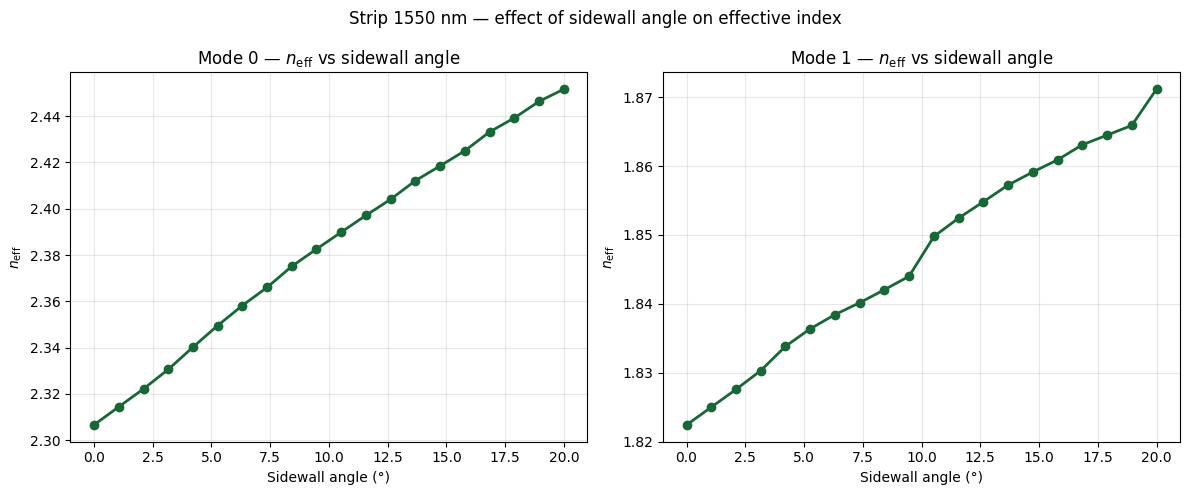

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

for mode_idx, ax in enumerate(axes):
    mode_df = results_df[results_df["mode_index"] == mode_idx].sort_values("sidewall_angle_deg")
    ax.plot(mode_df["sidewall_angle_deg"], mode_df["n_eff"], marker="o", linewidth=2)
    ax.set_xlabel("Sidewall angle (°)")
    ax.set_ylabel("$n_\\mathrm{eff}$")
    ax.set_title(f"Mode {mode_idx} — $n_\\mathrm{{eff}}$ vs sidewall angle")
    ax.grid(True, alpha=0.3)

plt.suptitle("Strip 1550 nm — effect of sidewall angle on effective index")
plt.tight_layout()
plt.show()